# Week 4 Capstone — Predicting Internship Selection Outcomes
This notebook builds a simple model to explore which application factors are linked to being selected.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

## Step 2: Dataset and simulated features
**Honesty note:** I have no real historical data, so this whole dataset is simulated, including the 4 new features (num_skills_listed, has_portfolio, prior_hackathon_participation, statement_quality_score) and the Status outcome. np.random.seed(42) makes it reproducible. In a real deployment, this data would have to be collected from real applications before the model could be trusted.

In [17]:
np.random.seed(42)
n = 300
df = pd.DataFrame({
 'Name': [f'Applicant {i}' for i in range(1, n+1)],
 'Email': [f'applicant{i}@example.com' for i in range(1, n+1)],
 'Domain Applied': np.random.choice(['Web Dev','Data Science','Graphic Design','AI/ML','Cybersecurity'], size=n)})
df['num_skills_listed'] = np.random.randint(1, 9, size=n)
df['has_portfolio'] = np.random.choice(['Yes','No'], size=n, p=[0.4,0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes','No'], size=n, p=[0.3,0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=n)

score = 0.5*df['statement_quality_score'] + 2*(df['has_portfolio']=='Yes') + 1*(df['prior_hackathon_participation']=='Yes') + 0.2*df['num_skills_listed']
prob = 1/(1+np.exp(-(score-5)))
df['Status'] = np.where(np.random.rand(n) < prob, 'Selected', 'Rejected')
review = np.random.choice(n, size=30, replace=False)
df.loc[review, 'Status'] = 'Under Review'
print(df['Status'].value_counts())
df.head()

Status
Rejected        144
Selected        126
Under Review     30
Name: count, dtype: int64


,Name,Email,Domain Applied,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,Status
0,Applicant 1,applicant1@example.com,AI/ML,5,No,No,5,Under Review
1,Applicant 2,applicant2@example.com,Cybersecurity,8,No,No,1,Rejected
2,Applicant 3,applicant3@example.com,Graphic Design,5,Yes,Yes,1,Rejected
3,Applicant 4,applicant4@example.com,Cybersecurity,1,No,No,10,Selected
4,Applicant 5,applicant5@example.com,Cybersecurity,6,No,No,9,Selected


## Step 3: Feature preparation
- Yes/No columns became 1/0 because models only understand numbers.
- target = 1 if Selected, 0 if Rejected. "Under Review" rows were dropped because they have no final outcome to learn from.
- Domain Applied was one-hot encoded (one 0/1 column per domain, with no fake ordering). drop_first=True removes one redundant column.
- Name and Email were excluded because they are identifiers, not meaningful signals.

In [18]:
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)
df_model = df[df['Status'] != 'Under Review'].copy()
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True, dtype=int)
feature_columns = ['num_skills_listed','has_portfolio','prior_hackathon_participation','statement_quality_score'] + [c for c in df_model.columns if c.startswith('Domain Applied_')]
X = df_model[feature_columns]
y = df_model['target']
X.head()

,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,Domain Applied_Cybersecurity,Domain Applied_Data Science,Domain Applied_Graphic Design,Domain Applied_Web Dev
1,8,0,0,1,1,0,0,0
2,5,1,1,1,0,0,1,0
3,1,0,0,10,1,0,0,0
4,6,0,0,9,1,0,0,0
5,5,1,0,7,0,1,0,0


## Step 4: Train/test split
80% of the data trains the model and 20% is kept hidden to test it honestly on unseen applicants. random_state=42 makes the split reproducible.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

Training rows: 216
Test rows: 54


## Step 5: Train the model
I used Logistic Regression, a standard model for yes/no predictions. .fit() is the learning step, where the model finds patterns linking features to outcomes.

In [20]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Step 6: Evaluation
- **Accuracy:** the share of test applicants predicted correctly.
- **Precision:** of those predicted Selected, how many really were Selected (fewer false promises).
- **Recall:** of those really Selected, how many the model caught (fewer missed candidates).
- **Confusion matrix:** a 2x2 grid of correct and incorrect predictions.

Accuracy: 90.74%
Precision: 92.59%
Recall: 89.29%


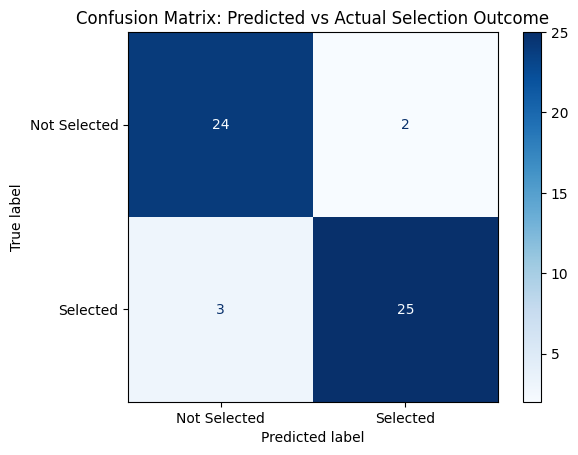

[[24  2]
 [ 3 25]]


In [21]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred):.2%}")
print(f"Recall: {recall_score(y_test, y_pred):.2%}")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected','Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: Predicted vs Actual Selection Outcome')
plt.show()
print(cm)

### Reading my results
My model reached 90.74% accuracy, 92.59% precision and 89.29% recall on 54 test applicants. The confusion matrix shows 25 correctly predicted Selected, 24 correctly predicted Not Selected, 2 false positives (predicted Selected but not) and 3 false negatives (missed Selected applicants).

In plain terms:
- **Accuracy:** about 91 out of every 100 test applicants were predicted correctly.
- **Precision:** when the model said "Selected", it was right about 93% of the time (25 out of 27).
- **Recall:** the model caught about 89% of the applicants who were truly Selected (25 out of 28).

These scores are high partly because the outcome was simulated from the same features the model learned from. A real dataset would almost certainly give lower and messier results.

### Limitations (honest)
- The dataset is small and fully simulated, including 4 features and the outcome, so these numbers illustrate the method and are not a production guarantee.
- With a small test set (54 rows), results can shift noticeably if the data is split differently.
- A real model like this could learn and repeat bias from past selection decisions, for example if certain universities were favoured for non-merit reasons.
- It should be a decision-support tool for human reviewers, never a replacement for them.

## Step 7: Which features mattered most?
A positive coefficient means the feature raises the chance of being predicted Selected, and a negative one lowers it. The larger the number, the stronger the effect.

In [22]:
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]}).sort_values(by='Coefficient', ascending=False)
print(coefficients)

                         Feature  Coefficient
1                  has_portfolio     2.202741
2  prior_hackathon_participation     0.891785
3        statement_quality_score     0.620062
6  Domain Applied_Graphic Design     0.438027
0              num_skills_listed     0.266192
7         Domain Applied_Web Dev     0.262545
5    Domain Applied_Data Science     0.163421
4   Domain Applied_Cybersecurity     0.128754


### Interpretation
The strongest positive predictor was **has_portfolio** (coefficient about 2.20), followed by **prior_hackathon_participation** (about 0.89) and **statement_quality_score** (about 0.62). Applicants with a portfolio or GitHub link had a much higher predicted chance of selection than those without one.

num_skills_listed (about 0.27) had a smaller effect, and the domain columns (about 0.13 to 0.44) were weaker still. No feature had a negative coefficient, so every input pushed the prediction toward "Selected" as it increased.

Domain coefficients are measured against the dropped domain (AI/ML), so they show how each domain compares with AI/ML and not an effect on their own.

This describes what the model learned from this simulated dataset. It is not a real finding about NextGenLearners' selection process, and it would need to be validated on real historical data. The model found an association, not proof that a portfolio causes selection.

## Executive Summary

**What we did:** We built a simple tool that looks at an applicant's details and predicts whether they are likely to be selected for the NextGenLearners internship. The goal was to see which things about an application are linked to being selected.

**What we found:** We tested the tool on 54 applicants it had never seen before, and it predicted the right outcome for about 91 out of every 100. When it said an applicant would be selected, it was right about 93% of the time. It also spotted about 89% of the applicants who really were selected.

The three things most linked to selection were:
1. Whether the applicant shared a portfolio or GitHub link (by far the strongest)
2. Whether they had taken part in a hackathon before
3. How strong their written statement was

How many skills they listed and which area they applied to mattered much less.

**Important caveats:** All the data in this exercise was made up by us, including the applicants, their details and who got selected, because we do not have real records yet. That is why the results look so good, and real data would almost certainly give lower and messier results. The test group was also small, so the numbers could change if we tested it again on different applicants. These results show that the method works, not how NextGenLearners really selects people. The tool must only help reviewers and never replace human judgment, because a tool like this can accidentally repeat unfair patterns from past decisions.

**Recommendation:** Add a required "portfolio / GitHub link" field to the application form, so this information is collected for every applicant and make it optional for candidate who are freshes so most Chances can be given . Then, after a few months of real applications, test the tool again on that real data.